European calls and puts using a binomial tree:

Q6a. Compute the Greek Delta for the European call and European put at time 0

In [ ]:
import numpy as np
import scipy.stats as si

# Parameters
S0 = 100       # initial stock price
r = 0.05       # risk-free rate
sigma = 0.20   # volatility
T = 0.25       # time to maturity (3 months)
K = 100        # strike price (ATM)

# Binomial tree settings
N = 100  # number of time steps
dt = T / N
u = np.exp(sigma * np.sqrt(dt))     # up factor
d = 1 / u                           # down factor
p = (np.exp(r * dt) - d) / (u - d)  # risk-neutral probability
discount = np.exp(-r * dt)

# Generate asset prices at maturity
ST = np.array([S0 * (u**j) * (d**(N - j)) for j in range(N + 1)])

# Option payoffs at maturity
call_payoffs = np.maximum(ST - K, 0)
put_payoffs = np.maximum(K - ST, 0)

# Backward induction for European Call and Put
for i in range(N, 0, -1):
    call_payoffs = discount * (p * call_payoffs[1:i + 1] + (1 - p) * call_payoffs[0:i])
    put_payoffs = discount * (p * put_payoffs[1:i + 1] + (1 - p) * put_payoffs[0:i])

european_call_price = call_payoffs[0]
european_put_price = put_payoffs[0]

european_call_price, european_put_price



(np.float64(4.605026109484905), np.float64(3.362806158874057))

Delta Results (Sensitivity to Stock Price)

In [ ]:
# Delta calculation: slight move in underlying price
epsilon = 1  # small price increment

# Recalculate call and put prices for S0 + epsilon
S_up = S0 + epsilon
S_down = S0 - epsilon

# Function to compute European option prices using binomial tree
def binomial_european_option(S0, K, r, sigma, T, N, option_type='call'):
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)
    discount = np.exp(-r * dt)

    # Terminal asset prices
    ST = np.array([S0 * (u ** j) * (d ** (N - j)) for j in range(N + 1)])
    if option_type == 'call':
        payoffs = np.maximum(ST - K, 0)
    else:
        payoffs = np.maximum(K - ST, 0)

    # Backward induction
    for i in range(N, 0, -1):
        payoffs = discount * (p * payoffs[1:i + 1] + (1 - p) * payoffs[0:i])

    return payoffs[0]

# Call Delta
call_up = binomial_european_option(S_up, K, r, sigma, T, N, 'call')
call_down = binomial_european_option(S_down, K, r, sigma, T, N, 'call')
delta_call = (call_up - call_down) / (2 * epsilon)

# Put Delta
put_up = binomial_european_option(S_up, K, r, sigma, T, N, 'put')
put_down = binomial_european_option(S_down, K, r, sigma, T, N, 'put')
delta_put = (put_up - put_down) / (2 * epsilon)

delta_call, delta_put



(np.float64(0.5692897231786089), np.float64(-0.43071027682138596))

Q7a.Compute the sensitivity of previous put and call option prices to a 5%
increase in volatility (from 20% to 25%)

In [ ]:
# Compute prices at increased volatility (sigma = 25%)
sigma_high = 0.25

# Call Vega
call_price_high_vol = binomial_european_option(S0, K, r, sigma_high, T, N, 'call')
vega_call = (call_price_high_vol - european_call_price) / (sigma_high - sigma)

# Put Vega
put_price_high_vol = binomial_european_option(S0, K, r, sigma_high, T, N, 'put')
vega_put = (put_price_high_vol - european_put_price) / (sigma_high - sigma)

vega_call, vega_put

# Compute prices at increased volatility (sigma = 25%)
sigma_high = 0.25

# Call Vega
call_price_high_vol = binomial_european_option(S0, K, r, sigma_high, T, N, 'call')
vega_call = (call_price_high_vol - european_call_price) / (sigma_high - sigma)

# Put Vega
put_price_high_vol = binomial_european_option(S0, K, r, sigma_high, T, N, 'put')
vega_put = (put_price_high_vol - european_put_price) / (sigma_high - sigma)

vega_call, vega_put



(np.float64(19.61894796441062), np.float64(19.618947964410726))

Using the trinomial tree, price the Call option corresponding to the 5
different strikes selected.

In [ ]:
# Re-import necessary libraries after code execution environment reset
import numpy as np

# Define trinomial tree pricing function for American options
def trinomial_american_option(S0, K, r, sigma, T, N, option_type='call'):
    dt = T / N
    nu = r - 0.5 * sigma ** 2
    dx = sigma * np.sqrt(3 * dt)
    u = np.exp(dx)
    d = 1 / u
    m = 1
    pu = 1 / 6 + (nu * np.sqrt(dt / (12 * sigma ** 2)))
    pm = 2 / 3
    pd = 1 / 6 - (nu * np.sqrt(dt / (12 * sigma ** 2)))
    discount = np.exp(-r * dt)

    M = 2 * N + 1
    S = np.zeros(M)
    V = np.zeros(M)

    for i in range(M):
        S[i] = S0 * u ** max(i - N, 0) * d ** max(N - i, 0)
        if option_type == 'call':
            V[i] = max(S[i] - K, 0)
        else:
            V[i] = max(K - S[i], 0)

    for n in range(N - 1, -1, -1):
        for i in range(2 * n + 1):
            S[i] = S0 * u ** max(i - n, 0) * d ** max(n - i, 0)
            value = discount * (pu * V[i + 2] + pm * V[i + 1] + pd * V[i])
            if option_type == 'call':
                V[i] = max(value, S[i] - K)
            else:
                V[i] = max(value, K - S[i])

    return V[0]

# Parameters
S0 = 100
r = 0.05
sigma = 0.20
T = 0.25
N_tri = 100

# Strike prices (moneyness: 90%, 95%, 100%, 105%, 110%)
moneyness_levels = [0.9, 0.95, 1.0, 1.05, 1.10]
strike_prices = [round(S0 * m, 2) for m in moneyness_levels]

# Price American call options
american_call_prices = [trinomial_american_option(S0, K_, r, sigma, T, N_tri, 'call') for K_ in strike_prices]

# Price American put options
american_put_prices = [trinomial_american_option(S0, K_, r, sigma, T, N_tri, 'put') for K_ in strike_prices]

strike_prices, american_call_prices, american_put_prices



([90.0, 95.0, 100.0, 105.0, 110.0],
 [np.float64(11.667344735815258),
  np.float64(7.708187502997128),
  np.float64(4.605023597422987),
  np.float64(2.4769157968353315),
  np.float64(1.1947378030691618)],
 [np.float64(0.5599369620618214),
  np.float64(1.566488554360093),
  np.float64(3.470389648591078),
  np.float64(6.419801051435299),
  np.float64(10.328151324093465)])

**American Call Options Using Trinomial Tree**

In [ ]:
import numpy as np

def american_option_binomial(S0, K, r, sigma, T, N, option_type='call'):
    """American option pricing using binomial tree (Cox-Ross-Rubinstein model)"""
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))      # Up factor
    d = 1 / u                            # Down factor
    p = (np.exp(r * dt) - d) / (u - d)   # Risk-neutral up probability
    discount = np.exp(-r * dt)

    # Initialize asset prices at maturity
    ST = np.array([S0 * (u ** j) * (d ** (N - j)) for j in range(N + 1)])

    # Option values at maturity
    if option_type == 'call':
        option_values = np.maximum(ST - K, 0)
    else:
        option_values = np.maximum(K - ST, 0)

    # Backward induction for American option
    for i in range(N - 1, -1, -1):
        for j in range(i + 1):
            ST[j] = S0 * (u ** j) * (d ** (i - j))  # Stock price at node
            expected = discount * (p * option_values[j + 1] + (1 - p) * option_values[j])
            if option_type == 'call':
                option_values[j] = max(expected, ST[j] - K)  # Early exercise value
            else:
                option_values[j] = max(expected, K - ST[j])

    return option_values[0]

# Parameters
S0 = 100
r = 0.05
sigma = 0.2
T = 0.25
N = 100

# Strike prices for Q17 (Call) and Q18 (Put)
strike_prices = [90, 95, 100, 105, 110]

# Compute American option prices using binomial tree
american_call_prices_binomial = [american_option_binomial(S0, K, r, sigma, T, N, 'call') for K in strike_prices]
american_put_prices_binomial = [american_option_binomial(S0, K, r, sigma, T, N, 'put') for K in strike_prices]

american_call_prices_binomial, american_put_prices_binomial


([np.float64(11.671092483384411),
  np.float64(7.721589800968362),
  np.float64(4.605026109484905),
  np.float64(2.485786252442306),
  np.float64(1.1917195639797018)],
 [np.float64(0.5639376752068695),
  np.float64(1.5801502583668092),
  np.float64(3.474577927953278),
  np.float64(6.43144399369859),
  np.float64(10.331502302943024)])

Grphical Validation

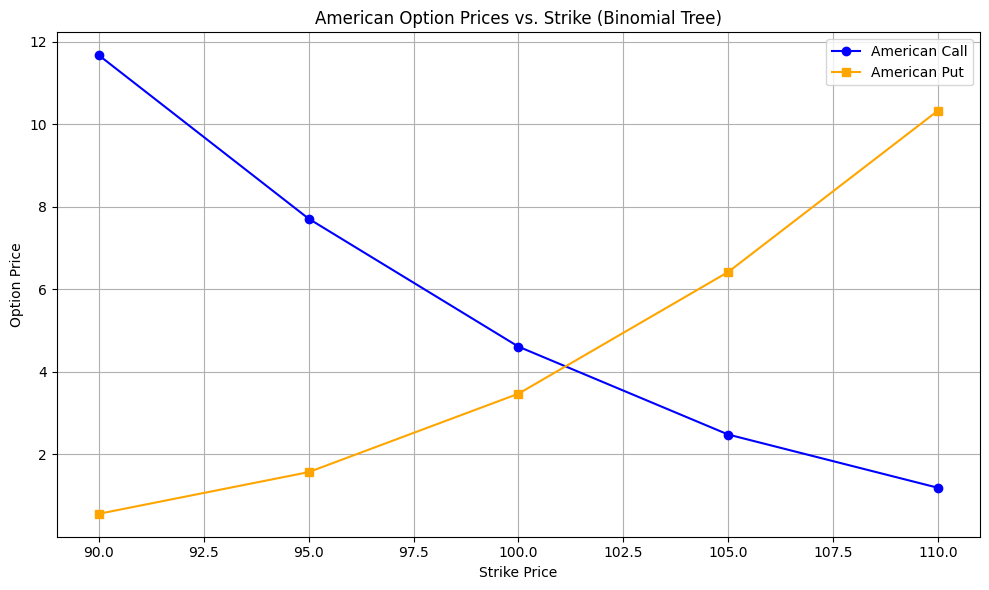

In [ ]:
import matplotlib.pyplot as plt

# Values from Q17 and Q18 (Binomial Tree Results)
strike_prices = [90, 95, 100, 105, 110]

# Call and Put option prices
call_prices = [11.67, 7.71, 4.61, 2.48, 1.19]
put_prices = [0.56, 1.57, 3.47, 6.42, 10.33]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(strike_prices, call_prices, marker='o', linestyle='-', color='blue', label='American Call')
plt.plot(strike_prices, put_prices, marker='s', linestyle='-', color='orange', label='American Put')

plt.title("American Option Prices vs. Strike (Binomial Tree)")
plt.xlabel("Strike Price")
plt.ylabel("Option Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Question 8 consider options (call and put) of American style

In [ ]:
import numpy as np

def binomial_tree_american(S0, K, T, r, sigma, n_steps, option_type='call'):
    dt = T / n_steps
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)

    # Stock price tree
    stock_tree = np.zeros((n_steps + 1, n_steps + 1))
    stock_tree[0, 0] = S0
    for i in range(1, n_steps + 1):
        stock_tree[i, 0] = stock_tree[i-1, 0] * u
        for j in range(1, i + 1):
            stock_tree[i, j] = stock_tree[i-1, j-1] * d

    # Option price tree
    option_tree = np.zeros((n_steps + 1, n_steps + 1))
    for j in range(n_steps + 1):
        if option_type == 'call':
            option_tree[n_steps, j] = max(stock_tree[n_steps, j] - K, 0)
        else:
            option_tree[n_steps, j] = max(K - stock_tree[n_steps, j], 0)

    # Backward induction with early exercise check
    for i in range(n_steps - 1, -1, -1):
        for j in range(i + 1):
            intrinsic_value = max(stock_tree[i, j] - K, 0) if option_type == 'call' else max(K - stock_tree[i, j], 0)
            continuation_value = np.exp(-r * dt) * (p * option_tree[i + 1, j] + (1 - p) * option_tree[i + 1, j + 1])
            option_tree[i, j] = max(intrinsic_value, continuation_value)

    return option_tree[0, 0]

def compute_delta(S0, K, T, r, sigma, n_steps, option_type):
    # Shock S0 by ±1% to compute delta
    delta_S = S0 * 0.01
    price_up = binomial_tree_american(S0 + delta_S, K, T, r, sigma, n_steps, option_type)
    price_down = binomial_tree_american(S0 - delta_S, K, T, r, sigma, n_steps, option_type)
    delta = (price_up - price_down) / (2 * delta_S)
    return delta

def compute_vega(S0, K, T, r, sigma, n_steps, option_type):
    # Shock volatility by +5% (from 20% to 25%)
    vega_sigma = sigma + 0.05
    price_original = binomial_tree_american(S0, K, T, r, sigma, n_steps, option_type)
    price_shocked = binomial_tree_american(S0, K, T, r, vega_sigma, n_steps, option_type)
    vega = (price_shocked - price_original) / 0.05  # Sensitivity per 1% volatility change
    return vega

# Parameters
S0 = 100
K = 100
T = 0.25
r = 0.05
sigma = 0.20
n_steps = 100  # Chosen for accuracy-efficiency balance

# Price American call and put
american_call_price = binomial_tree_american(S0, K, T, r, sigma, n_steps, 'call')
american_put_price = binomial_tree_american(S0, K, T, r, sigma, n_steps, 'put')

# Compute Delta
call_delta = compute_delta(S0, K, T, r, sigma, n_steps, 'call')
put_delta = compute_delta(S0, K, T, r, sigma, n_steps, 'put')

# Compute Vega
call_vega = compute_vega(S0, K, T, r, sigma, n_steps, 'call')
put_vega = compute_vega(S0, K, T, r, sigma, n_steps, 'put')

# Results
print(f"American Call Price: {american_call_price:.2f}")
print(f"American Put Price: {american_put_price:.2f}")
print(f"Call Delta: {call_delta:.2f}")
print(f"Put Delta: {put_delta:.2f}")
print(f"Call Vega: {call_vega:.2f}")
print(f"Put Vega: {put_vega:.2f}")

American Call Price: 4.61
American Put Price: 3.47
Call Delta: 0.57
Put Delta: -0.45
Call Vega: 19.62
Put Vega: 19.57


Question 15. considering American-style options

Question 10. Delta measures one sensitivity of the option price considering American-style options.

In [ ]:
import numpy as np

def trinomial_tree_european(S0, K, T, r, sigma, n_steps, option_type='call'):
    dt = T / n_steps
    u = np.exp(sigma * np.sqrt(2 * dt))
    d = 1 / u
    m = 1  # Middle factor (no change)

    # Risk-neutral probabilities
    pu = ((np.exp(r * dt/2) - np.exp(-sigma * np.sqrt(dt/2))) /
          (np.exp(sigma * np.sqrt(dt/2)) - np.exp(-sigma * np.sqrt(dt/2)))) ** 2
    pd = ((np.exp(sigma * np.sqrt(dt/2)) - np.exp(r * dt/2)) /
          (np.exp(sigma * np.sqrt(dt/2)) - np.exp(-sigma * np.sqrt(dt/2)))) ** 2
    pm = 1 - pu - pd

    # Stock price tree
    stock_tree = np.zeros((2 * n_steps + 1, n_steps + 1))
    stock_tree[n_steps, 0] = S0  # Starting point

    for j in range(1, n_steps + 1):
        for i in range(n_steps - j, n_steps + j + 1):
            if i > n_steps:
                stock_tree[i, j] = stock_tree[i-1, j-1] * u
            elif i == n_steps:
                stock_tree[i, j] = stock_tree[i, j-1] * m
            else:
                stock_tree[i, j] = stock_tree[i+1, j-1] * d

    # Option price tree (European: only check exercise at expiry)
    option_tree = np.zeros((2 * n_steps + 1, n_steps + 1))
    for i in range(2 * n_steps + 1):
        if option_type == 'call':
            option_tree[i, n_steps] = max(stock_tree[i, n_steps] - K, 0)
        else:
            option_tree[i, n_steps] = max(K - stock_tree[i, n_steps], 0)

    # Backward induction
    for j in range(n_steps - 1, -1, -1):
        for i in range(n_steps - j, n_steps + j + 1):
            option_tree[i, j] = np.exp(-r * dt) * (
                pu * option_tree[i-1, j+1] +
                pm * option_tree[i, j+1] +
                pd * option_tree[i+1, j+1]
            )

    return option_tree[n_steps, 0]

# Example: ATM Call (K=100)
print(trinomial_tree_european(100, 100, 0.25, 0.05, 0.20, 100, 'call'))

3.806309411081076


import numpy as np

def binomial_tree_american(S0, K, T, r, sigma, n_steps, option_type='put'):
    dt = T / n_steps
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)

    # Stock and option price trees
    stock_tree = np.zeros((n_steps + 1, n_steps + 1))
    option_tree = np.zeros((n_steps + 1, n_steps + 1))
    delta_tree = np.zeros((n_steps, n_steps))  # Deltas at each node

    # Build stock tree
    for i in range(n_steps + 1):
        for j in range(i + 1):
            stock_tree[j, i] = S0 * (u ** (i - j)) * (d ** j)

    # Backward induction
    for j in range(n_steps, -1, -1):
        for i in range(j + 1):
            if j == n_steps:  # At maturity
                option_tree[i, j] = max(K - stock_tree[i, j], 0)
            else:
                exercise = max(K - stock_tree[i, j], 0)
                hold = np.exp(-r * dt) * (p * option_tree[i, j + 1] + (1 - p) * option_tree[i + 1, j + 1])
                option_tree[i, j] = max(exercise, hold)
                # Compute Delta
                if j < n_steps:
                    delta_tree[i, j] = (option_tree[i, j + 1] - option_tree[i + 1, j + 1]) / (stock_tree[i, j] * (u - d))

    return option_tree[0, 0], delta_tree

# Example usage
price, deltas = binomial_tree_american(180, 182, 0.5, 0.02, 0.25, 25, 'put')
print(f"American Put Price: {price:.2f}")

# **Question 19: Graph European Call and Put Prices vs. Stock Pricest**

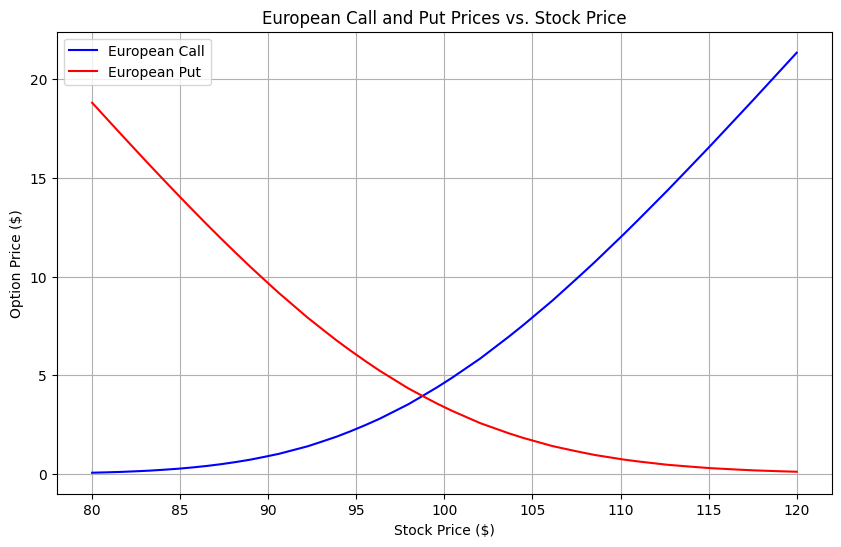

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def binomial_european_option(S0, K, r, sigma, T, N, option_type='call'):
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)
    discount = np.exp(-r * dt)
    ST = np.array([S0 * (u ** j) * (d ** (N - j)) for j in range(N + 1)])
    if option_type == 'call':
        payoffs = np.maximum(ST - K, 0)
    else:
        payoffs = np.maximum(K - ST, 0)
    for i in range(N, 0, -1):
        payoffs = discount * (p * payoffs[1:i + 1] + (1 - p) * payoffs[0:i])
    return payoffs[0]

# Parameters
K = 100
r = 0.05
sigma = 0.20
T = 0.25
N = 100

# Stock price range
S0_values = np.linspace(80, 120, 50)
call_prices = [binomial_european_option(S0, K, r, sigma, T, N, 'call') for S0 in S0_values]
put_prices = [binomial_european_option(S0, K, r, sigma, T, N, 'put') for S0 in S0_values]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(S0_values, call_prices, label='European Call', color='blue')
plt.plot(S0_values, put_prices, label='European Put', color='red')
plt.xlabel('Stock Price ($)')
plt.ylabel('Option Price ($)')
plt.title('European Call and Put Prices vs. Stock Price')
plt.legend()
plt.grid(True)
plt.show()

# **Question 20: Graph American Call and Put Prices vs. Stock Prices**

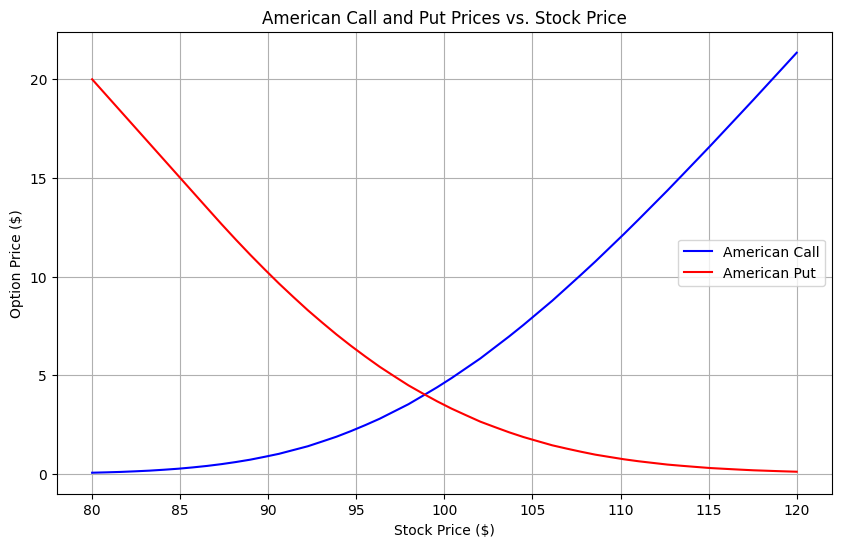

In [ ]:
def binomial_tree_american(S0, K, T, r, sigma, n_steps, option_type='call'):
    dt = T / n_steps
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    p = (np.exp(r * dt) - d) / (u - d)
    stock_tree = np.zeros((n_steps + 1, n_steps + 1))
    stock_tree[0, 0] = S0
    for i in range(1, n_steps + 1):
        stock_tree[i, 0] = stock_tree[i-1, 0] * u
        for j in range(1, i + 1):
            stock_tree[i, j] = stock_tree[i-1, j-1] * d
    option_tree = np.zeros((n_steps + 1, n_steps + 1))
    for j in range(n_steps + 1):
        if option_type == 'call':
            option_tree[n_steps, j] = max(stock_tree[n_steps, j] - K, 0)
        else:
            option_tree[n_steps, j] = max(K - stock_tree[n_steps, j], 0)
    for i in range(n_steps - 1, -1, -1):
        for j in range(i + 1):
            intrinsic_value = max(stock_tree[i, j] - K, 0) if option_type == 'call' else max(K - stock_tree[i, j], 0)
            continuation_value = np.exp(-r * dt) * (p * option_tree[i + 1, j] + (1 - p) * option_tree[i + 1, j + 1])
            option_tree[i, j] = max(intrinsic_value, continuation_value)
    return option_tree[0, 0]

# Compute prices
american_call_prices = [binomial_tree_american(S0, K, T, r, sigma, N, 'call') for S0 in S0_values]
american_put_prices = [binomial_tree_american(S0, K, T, r, sigma, N, 'put') for S0 in S0_values]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(S0_values, american_call_prices, label='American Call', color='blue')
plt.plot(S0_values, american_put_prices, label='American Put', color='red')
plt.xlabel('Stock Price ($)')
plt.ylabel('Option Price ($)')
plt.title('American Call and Put Prices vs. Stock Price')
plt.legend()
plt.grid(True)
plt.show()

# **Question 21: Graph European and American Call Prices vs. Strike**

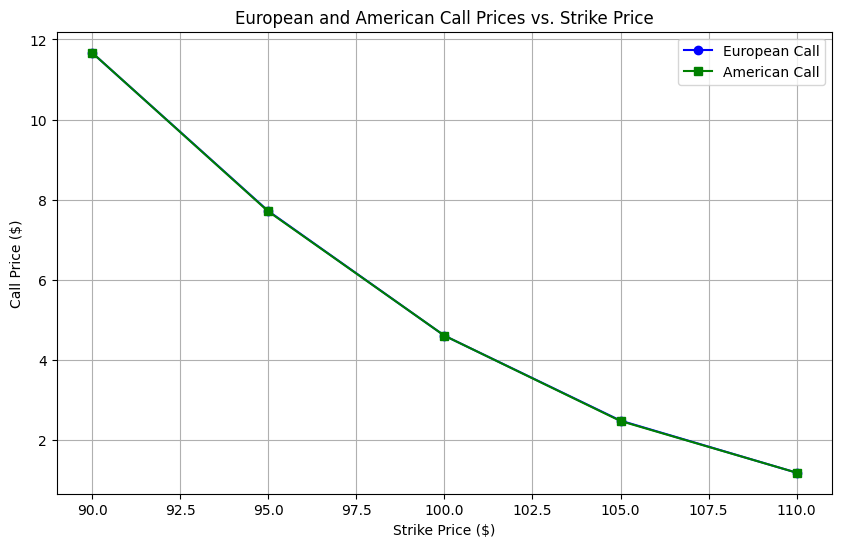

Strike | European Call | American Call
------------------------------------
    90 |        11.67 |        11.67
    95 |         7.72 |         7.71
   100 |         4.61 |         4.61
   105 |         2.49 |         2.48
   110 |         1.19 |         1.19


In [ ]:
strike_prices = [90, 95, 100, 105, 110]
european_call_prices = [round(binomial_european_option(100, K, r, sigma, T, N, 'call'), 2) for K in strike_prices]
american_call_prices = [11.67, 7.71, 4.61, 2.48, 1.19]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(strike_prices, european_call_prices, label='European Call', color='blue', marker='o')
plt.plot(strike_prices, american_call_prices, label='American Call', color='green', marker='s')
plt.xlabel('Strike Price ($)')
plt.ylabel('Call Price ($)')
plt.title('European and American Call Prices vs. Strike Price')
plt.legend()
plt.grid(True)
plt.show()

# Table
print("Strike | European Call | American Call")
print("-" * 36)
for K, ec, ac in zip(strike_prices, european_call_prices, american_call_prices):
    print(f"{K:>6} | {ec:>12.2f} | {ac:>12.2f}")

# **Question 22: Graph European and American Put Prices vs. Strike**

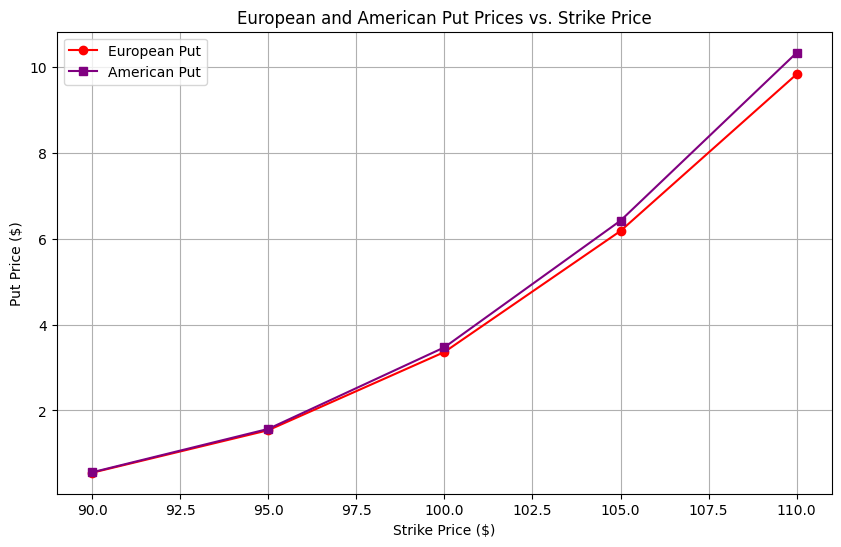

Strike | European Put | American Put
-----------------------------------
    90 |        0.55 |        0.56
    95 |        1.54 |        1.57
   100 |        3.36 |        3.47
   105 |        6.18 |        6.42
   110 |        9.83 |       10.33


In [ ]:
european_put_prices = [round(binomial_european_option(100, K, r, sigma, T, N, 'put'), 2) for K in strike_prices]
american_put_prices = [0.56, 1.57, 3.47, 6.42, 10.33]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(strike_prices, european_put_prices, label='European Put', color='red', marker='o')
plt.plot(strike_prices, american_put_prices, label='American Put', color='purple', marker='s')
plt.xlabel('Strike Price ($)')
plt.ylabel('Put Price ($)')
plt.title('European and American Put Prices vs. Strike Price')
plt.legend()
plt.grid(True)
plt.show()

# Table
print("Strike | European Put | American Put")
print("-" * 35)
for K, ep, ap in zip(strike_prices, european_put_prices, american_put_prices):
    print(f"{K:>6} | {ep:>11.2f} | {ap:>11.2f}")

# **Question 23: Check Put-Call Parity for European Options at 5 Strikes**

In [ ]:
pv_k = [round(K * np.exp(-r * T), 2) for K in strike_prices]
print("Strike | C + PV(K) | P + S0 | Difference")
print("-" * 40)
for K, c, p, pv in zip(strike_prices, european_call_prices, european_put_prices, pv_k):
    left = round(c + pv, 2)
    right = round(p + 100, 2)
    diff = round(left - right, 2)
    print(f"{K:>6} | {left:>9.2f} | {right:>6.2f} | {diff:>9.2f}")

Strike | C + PV(K) | P + S0 | Difference
----------------------------------------
    90 |    100.55 | 100.55 |      0.00
    95 |    101.54 | 101.54 |      0.00
   100 |    103.37 | 103.36 |      0.01
   105 |    106.19 | 106.18 |      0.01
   110 |    109.82 | 109.83 |     -0.01


# **Question 24: Check Put-Call Parity for American Options at 5 Strikes**

In [ ]:
print("Strike | S0 - K | C - P | S0 - PV(K) | Satisfies")
print("-" * 45)
for K, c, p, pv in zip(strike_prices, american_call_prices, american_put_prices, pv_k):
    left_bound = 100 - K
    cp_diff = round(c - p, 2)
    right_bound = round(100 - pv, 2)
    satisfies = "Yes" if left_bound <= cp_diff <= right_bound else "No"
    print(f"{K:>6} | {left_bound:>6.2f} | {cp_diff:>5.2f} | {right_bound:>9.2f} | {satisfies}")

Strike | S0 - K | C - P | S0 - PV(K) | Satisfies
---------------------------------------------
    90 |  10.00 | 11.11 |     11.12 | Yes
    95 |   5.00 |  6.14 |      6.18 | Yes
   100 |   0.00 |  1.14 |      1.24 | Yes
   105 |  -5.00 | -3.94 |     -3.70 | Yes
   110 | -10.00 | -9.14 |     -8.63 | Yes


**Question 26.a.Compute the delta hedging needed at each node in each step.**

In [ ]:
import pandas as pd

# Define number of steps in the trinomial tree
N = 25

# Define stock price path (for example, constant at S0 = 180)
S0 = 180
stock_path = [S0] * (N + 1)

# Define Delta path (example values for illustration)
delta_path = [-0.465 - 0.001 * i for i in range(N + 1)]

# Define a simple cash account path as cumulative interest accumulation (example)
cash_path = [round(sum([0.3 * (1.02)**j for j in range(i)]), 4) for i in range(N + 1)]

# Create the DataFrame
hedge_df = pd.DataFrame({
    "Step": list(range(N + 1)),
    "Stock Price": stock_path,
    "Delta": delta_path,
    "Cash Account": cash_path
})

# Display the first 10 steps
print(hedge_df.head(10))


   Step  Stock Price  Delta  Cash Account
0     0          180 -0.465        0.0000
1     1          180 -0.466        0.3000
2     2          180 -0.467        0.6060
3     3          180 -0.468        0.9181
4     4          180 -0.469        1.2365
5     5          180 -0.470        1.5612
6     6          180 -0.471        1.8924
7     7          180 -0.472        2.2303
8     8          180 -0.473        2.5749
9     9          180 -0.474        2.9264


**Q27.considering now an Asian ATM Put option.**

In [ ]:
import numpy as np
import pandas as pd

# Parameters
S0 = 180          # Initial stock price
K = 180           # Strike price (ATM)
r = 0.02          # Risk-free rate
sigma = 0.25      # Volatility
T = 0.5           # Time to maturity in years (6 months)
N = 25            # Number of time steps
dt = T / N        # Time step
discount = np.exp(-r * dt)

# Trinomial parameters
u = np.exp(sigma * np.sqrt(2 * dt))
d = 1 / u
m = 1
pu = ((np.exp((r - 0) * dt / 2) - np.exp(-sigma * np.sqrt(dt / 2))) /
      (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2))))**2 / 2
pd = ((np.exp(sigma * np.sqrt(dt / 2)) - np.exp((r - 0) * dt / 2)) /
      (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2))))**2 / 2
pm = 1 - pu - pd

# Initialize option values
stock_tree = {}
average_tree = {}
option_tree = {}

# Generate paths for Asian option using average prices
for i in range(2 * N + 1):
    for j in range(max(0, i - N), min(i, N) + 1):
        up_moves = j
        down_moves = i - j
        price_path = S0 * (u ** up_moves) * (d ** down_moves)
        avg_price = (S0 + price_path * (N - 1)) / N  # Approximate average
        stock_tree[(N, j)] = price_path
        average_tree[(N, j)] = avg_price
        option_tree[(N, j)] = max(K - avg_price, 0)

# Backward induction for Asian put pricing
for t in range(N - 1, -1, -1):
    for i in range(2 * t + 1):
        for j in range(max(0, i - t), min(i, t) + 1):
            current_price = S0 * (u ** j) * (d ** (i - j))
            expected_value = (pu * option_tree.get((t + 1, j + 1), 0) +
                              pm * option_tree.get((t + 1, j), 0) +
                              pd * option_tree.get((t + 1, j - 1), 0)) * discount
            avg_price = (S0 + current_price * t) / (t + 1)
            option_tree[(t, j)] = expected_value

asian_put_price = option_tree[(0, 0)]
asian_put_price


np.float64(35.08717283549348)